## Занятие 8. Визуализация связей (Scatter plots и парные графики)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
df = pd.read_csv('marketing_data.csv')
numeric_cols = ['TV_Spend', 'Radio_Spend', 'Social_Spend', 'Visits', 'Conversions', 'Sales']
print('Размер данных:', df.shape)
print('Пропуски по столбцам:', int(df.isna().sum().sum()))
df.head()

Размер данных: (250, 7)
Пропуски по столбцам: 0


,TV_Spend,Radio_Spend,Social_Spend,Visits,Conversions,Sales,Product_Category
0,6.8,4.5,2.4,23,2,14.100000,C
1,44.4,16.5,8.1,171,38,95.100000,D
2,46.6,24.6,18.7,178,63,81.994843,B
3,22.3,9.1,13.6,107,22,56.800000,B
4,19.4,13.0,13.0,73,19,54.100000,A


### Задание 1. Scatter plot: TV-бюджет и продажи

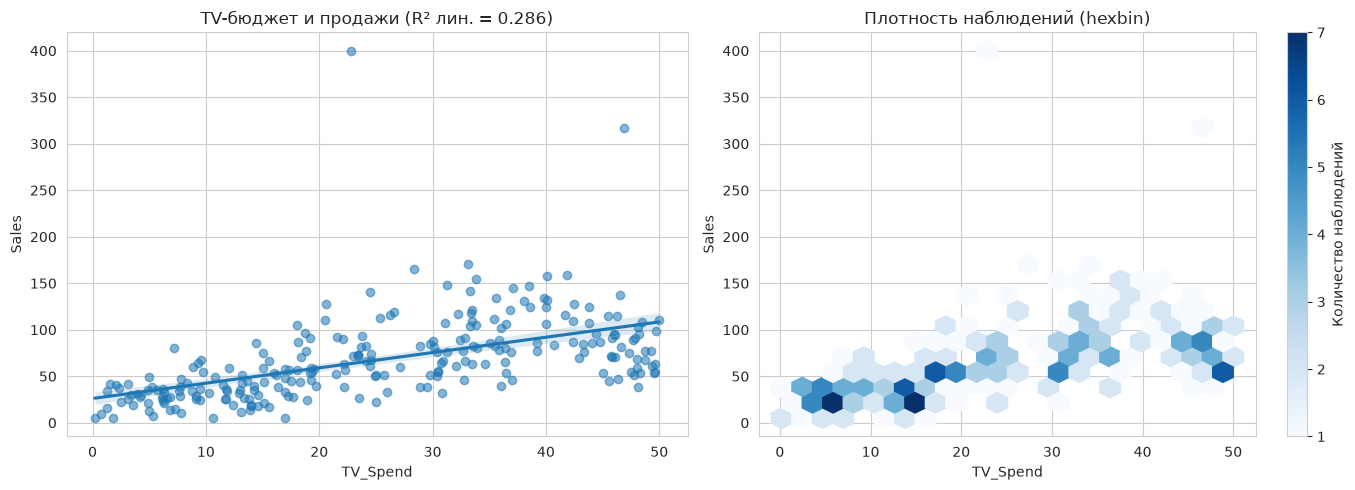

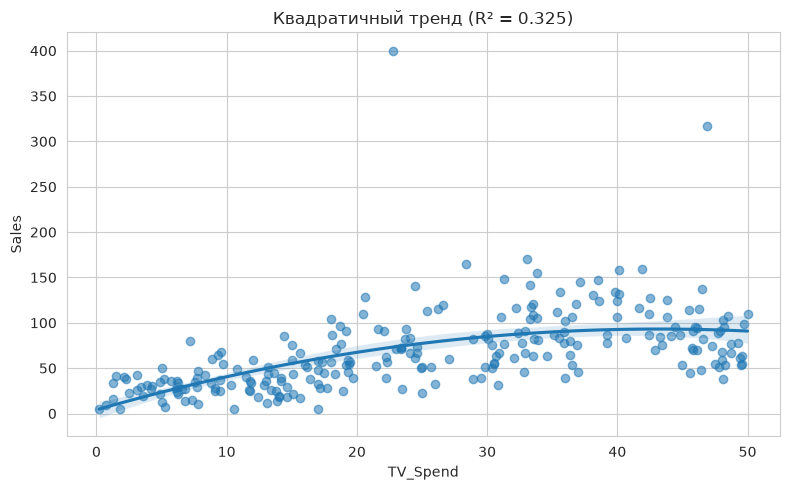

Квадратичная модель: Sales ≈ -0.0478·TV² + 4.128·TV + 4.014
Вершина параболы: TV ≈ 43.2 (максимум данных: TV = 50.0)
R² линейной модели:      0.286
R² квадратичной модели:  0.325


In [2]:
def r2(x, y, order=1):
    coef = np.polyfit(x, y, order)
    pred = np.polyval(coef, x)
    ss_res = ((y - pred) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=df, x='TV_Spend', y='Sales', ci=95, scatter_kws={'alpha': 0.55}, ax=axes[0])
axes[0].set_title(f'TV-бюджет и продажи (R² лин. = {r2(df.TV_Spend, df.Sales):.3f})')
hb = axes[1].hexbin(df['TV_Spend'], df['Sales'], gridsize=22, cmap='Blues', mincnt=1)
fig.colorbar(hb, ax=axes[1], label='Количество наблюдений')
axes[1].set(xlabel='TV_Spend', ylabel='Sales', title='Плотность наблюдений (hexbin)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='TV_Spend', y='Sales', order=2, ci=95, scatter_kws={'alpha': 0.55})
plt.title(f'Квадратичный тренд (R² = {r2(df.TV_Spend, df.Sales, order=2):.3f})')
plt.tight_layout()
plt.show()

coef2 = np.polyfit(df['TV_Spend'], df['Sales'], 2)
print(f'Квадратичная модель: Sales ≈ {coef2[0]:.4f}·TV² + {coef2[1]:.3f}·TV + {coef2[2]:.3f}')
print(f'Вершина параболы: TV ≈ {-coef2[1] / (2 * coef2[0]):.1f} (максимум данных: TV = {df.TV_Spend.max()})')
print(f'R² линейной модели:      {r2(df.TV_Spend, df.Sales):.3f}')
print(f'R² квадратичной модели:  {r2(df.TV_Spend, df.Sales, order=2):.3f}')

### Задание 2. Цветовая кодировка по категории и размер точек по посещениям

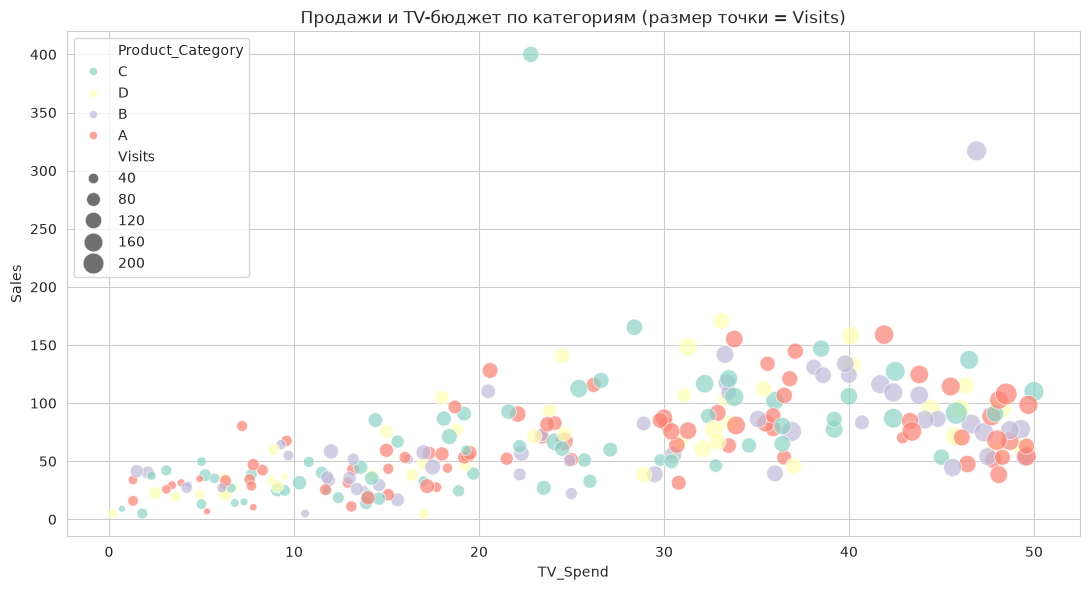

Продажи по категориям:
                  count   mean  median
Product_Category                      
A                    82  65.72   63.23
B                    53  70.53   56.80
C                    67  66.93   53.50
D                    48  69.38   66.85

Медианы продаж внутри квартилей TV-бюджета:
Product_Category     A     B     C     D
TV_группа                               
(0.199, 13.2]     31.4  36.1  27.0  25.6
(13.2, 24.3]      56.3  45.1  59.4  59.6
(24.3, 36.725]    81.4  69.0  72.6  79.9
(36.725, 50.0]    75.8  85.7  91.4  95.0


In [2]:
plt.figure(figsize=(11, 6))
sns.scatterplot(data=df, x='TV_Spend', y='Sales', hue='Product_Category', size='Visits', sizes=(25, 250), alpha=0.7)
plt.title('Продажи и TV-бюджет по категориям (размер точки = Visits)')
plt.tight_layout()
plt.show()

print('Продажи по категориям:')
print(df.groupby('Product_Category')['Sales'].agg(['count', 'mean', 'median']).round(2))
print()
print('Медианы продаж внутри квартилей TV-бюджета:')
quartile_medians = df.assign(TV_группа=pd.qcut(df['TV_Spend'], 4)).groupby(['TV_группа', 'Product_Category'], observed=True)['Sales'].median().unstack().round(1)
print(quartile_medians)

### Задание 3. Матрица диаграмм рассеяния (pairplot)

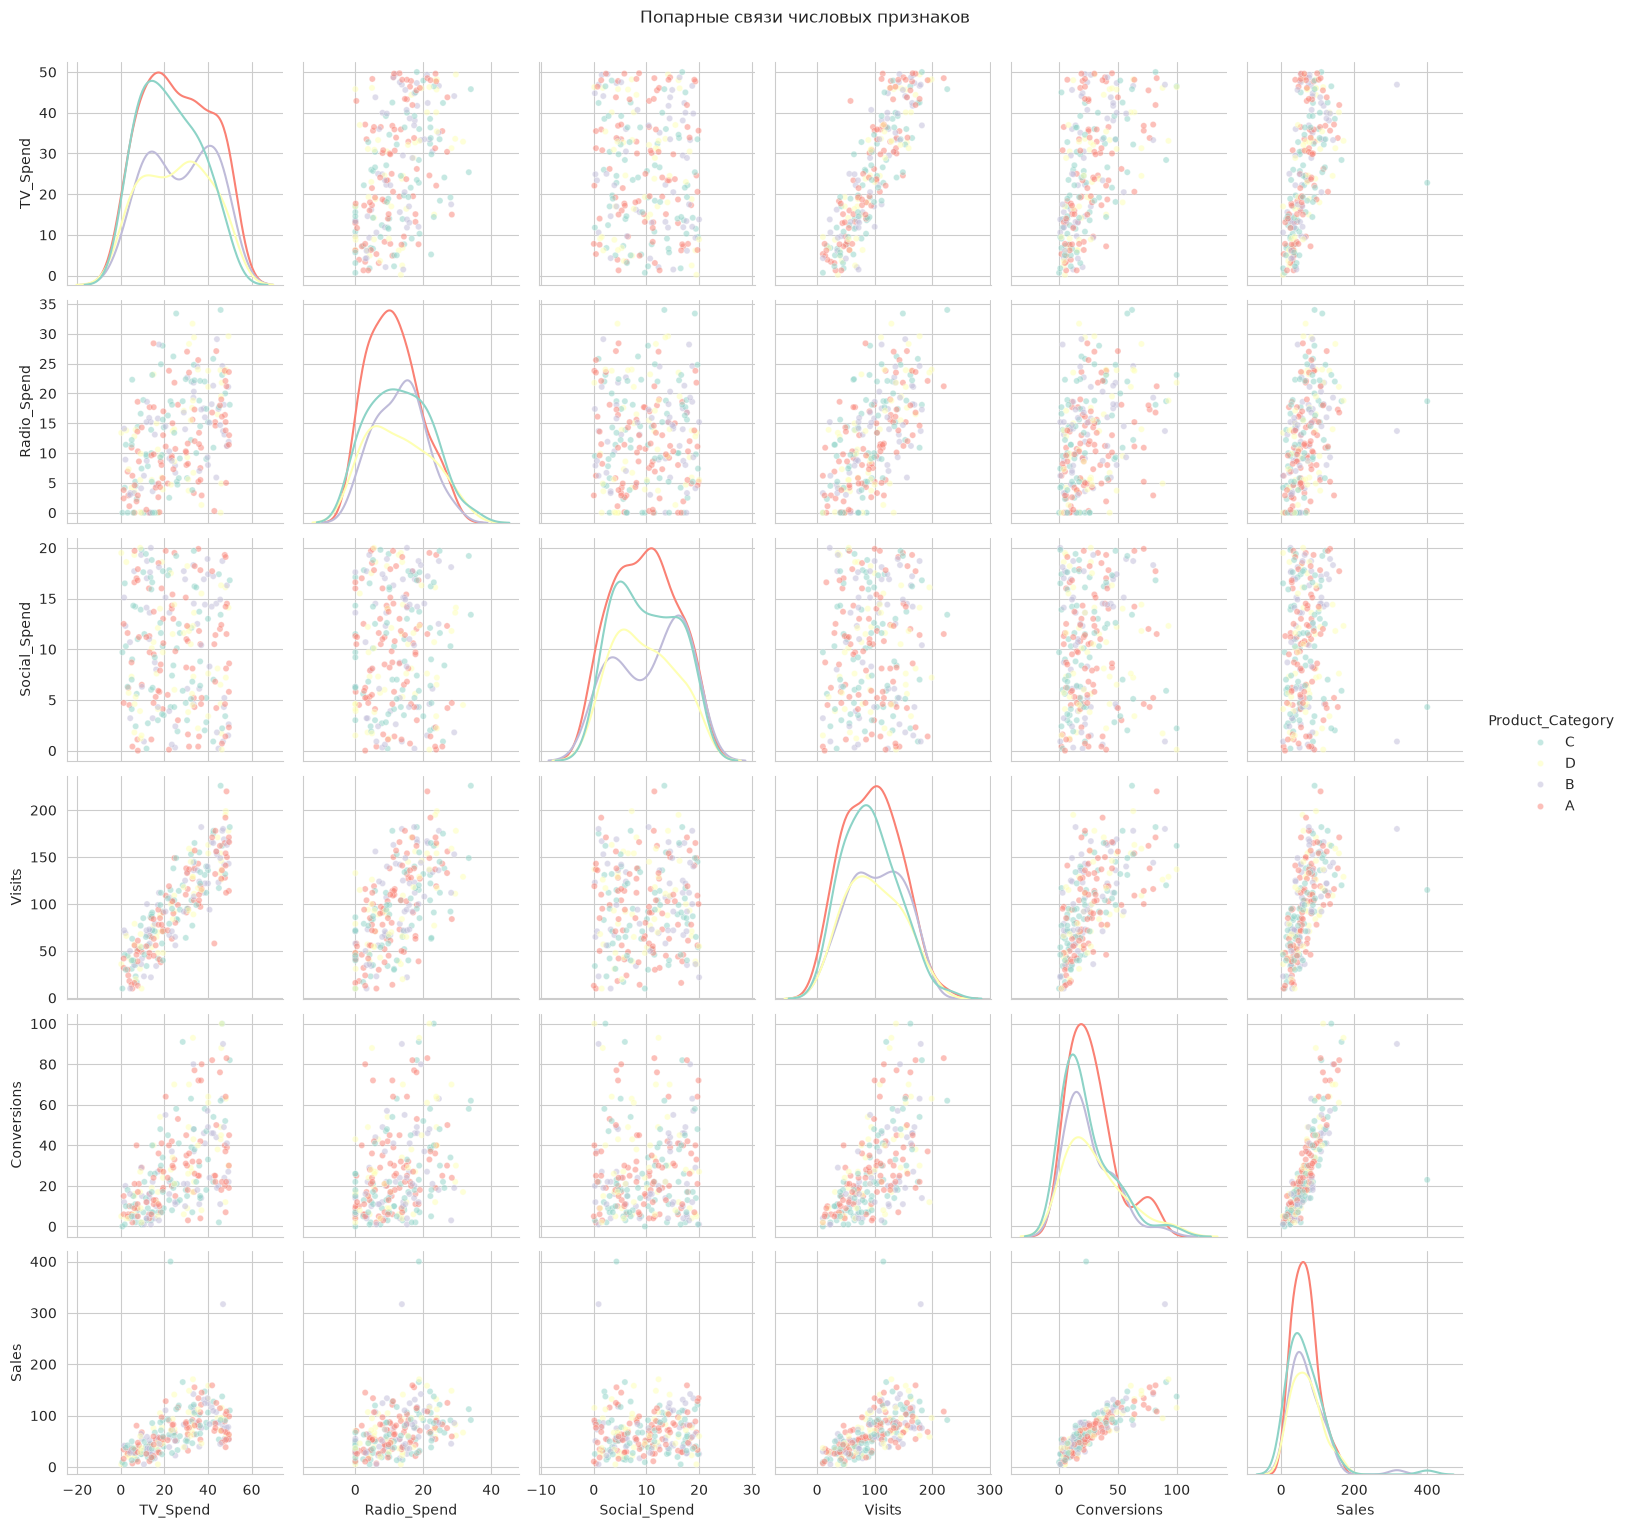

Самые сильные парные корреляции:
TV_Spend     Visits         0.869
Conversions  Sales          0.760
Radio_Spend  Visits         0.630
Visits       Conversions    0.620
             Sales          0.588
TV_Spend     Conversions    0.560
dtype: float64

Самые слабые пары:
Sales  Visits        NaN
       Conversions   NaN
       Sales         NaN
dtype: float64


In [3]:
grid = sns.pairplot(df, vars=numeric_cols, hue='Product_Category', diag_kind='kde', plot_kws={'alpha': 0.5, 's': 20}, diag_kws={'fill': False})
grid.fig.suptitle('Попарные связи числовых признаков', y=1.02)
plt.show()

corr = df[numeric_cols].corr()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print('Самые сильные парные корреляции:')
print(pairs.head(6).round(3))
print()
print('Самые слабые пары:')
print(pairs.tail(3).round(3))

### Задание 4. Joint plot и логарифмическое преобразование

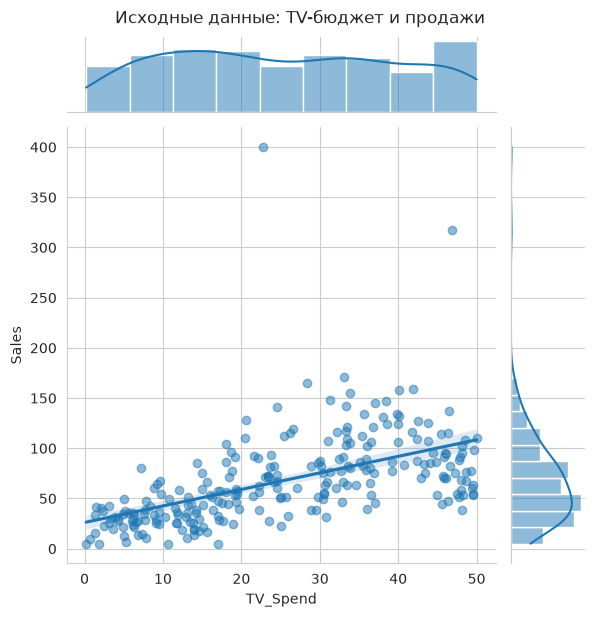

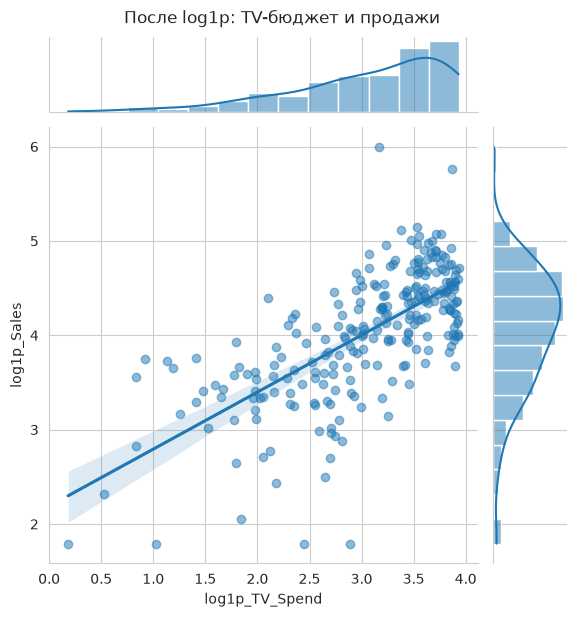

Корреляция Пирсона до преобразования:    0.535
Корреляция Пирсона после преобразования: 0.683
Асимметрия до:   {'TV_Spend': 0.09, 'Sales': 2.56}
Асимметрия после: {'log1p_TV_Spend': -1.1, 'log1p_Sales': -0.73}


In [5]:
g = sns.jointplot(data=df, x='TV_Spend', y='Sales', kind='reg', height=6, scatter_kws={'alpha': 0.5})
g.fig.suptitle('Исходные данные: TV-бюджет и продажи', y=1.02)
plt.show()

log_df = df[['TV_Spend', 'Sales']].apply(np.log1p).rename(columns={'TV_Spend': 'log1p_TV_Spend', 'Sales': 'log1p_Sales'})
g = sns.jointplot(data=log_df, x='log1p_TV_Spend', y='log1p_Sales', kind='reg', height=6, scatter_kws={'alpha': 0.5})
g.fig.suptitle('После log1p: TV-бюджет и продажи', y=1.02)
plt.show()

print(f'Корреляция Пирсона до преобразования:    {df.TV_Spend.corr(df.Sales):.3f}')
print(f'Корреляция Пирсона после преобразования: {log_df.log1p_TV_Spend.corr(log_df.log1p_Sales):.3f}')
print('Асимметрия до:  ', df[['TV_Spend', 'Sales']].skew().round(2).to_dict())
print('Асимметрия после:', log_df.skew().round(2).to_dict())

### Задание 5. Тепловая карта корреляций и интерпретация

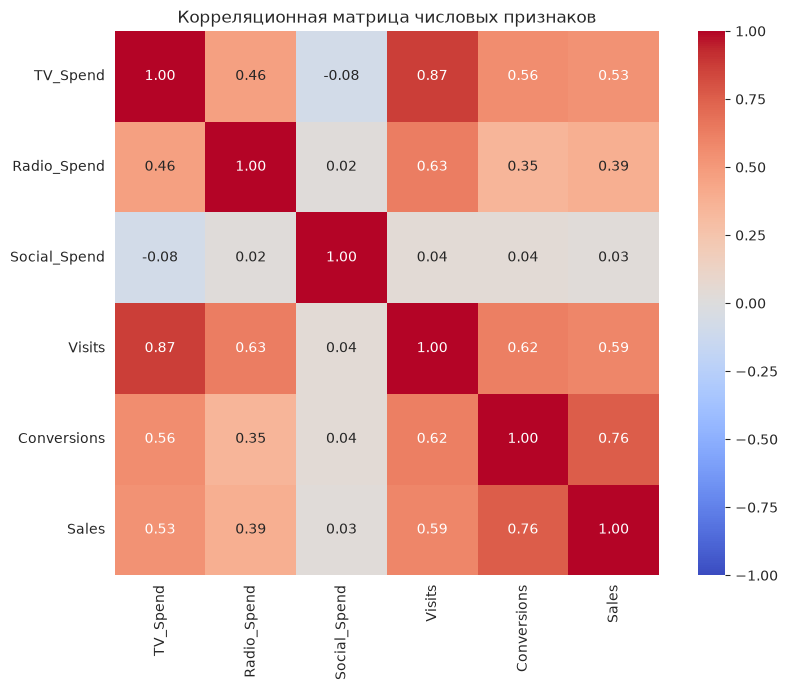

Связь признаков с Sales:
Conversions     0.760
Visits          0.588
TV_Spend        0.535
Radio_Spend     0.388
Social_Spend    0.031
Name: Sales, dtype: float64

Взаимные корреляции рекламных бюджетов (мультиколлинеарность):
              TV_Spend  Radio_Spend  Social_Spend
TV_Spend         1.000        0.461        -0.083
Radio_Spend      0.461        1.000         0.018
Social_Spend    -0.083        0.018         1.000


In [6]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

print('Связь признаков с Sales:')
print(corr['Sales'].drop('Sales').sort_values(ascending=False).round(3))
print()
print('Взаимные корреляции рекламных бюджетов (мультиколлинеарность):')
print(corr.loc[['TV_Spend', 'Radio_Spend', 'Social_Spend'], ['TV_Spend', 'Radio_Spend', 'Social_Spend']].round(3))